# tspanels: API walkthrough

This notebook presents the API of `tspanels` on one synthetic data set: hourly readings of an ocean mooring in
a tropical sea over 14 days, with a marine heat wave, a tropical storm, a phytoplankton bloom after the storm,
and an outage without readings. Each section introduces one part of the API and draws the figure that it
produces.

1. Data and the smallest call.
2. The layout: panels, lines, and the shorthand forms.
3. Input forms: a time index, a time column, a dict of Series, a polars DataFrame.
4. Annotations of one panel and of the whole figure.
5. The window around an event, and the gap markers.
6. A project-level plotting function built on `plot_panels`.
7. Colors, user-defined annotations, the building blocks, and the theme for other plots.
8. The errors raised for an inconsistent layout.

The notebook is run from the directory `notebooks/` with the environment of the repository (`uv sync`); the
package is installed there in editable mode. It reads no files and writes none. The data are generated in the
notebook; their values are plausible for a tropical sea but do not describe a real place or a real storm.

## Setup

In [1]:
import functools
from dataclasses import dataclass

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from tspanels import (
    DEFAULT_STYLE, Band, Line, Note, Panel, Points, RefLine, Span, Style, VLine, as_panels, draw_panel,
    format_time_axis, plot_panels, rc_params, required_columns, set_default_style, style_axis, to_frame,
)

HOUR = pd.Timedelta(hours=1)

## Example data

The table holds one row per hour from 4 to 17 March 2024. Its columns are:

- `wind`: the wind speed at 4 m above the sea surface, in m/s; trade winds of about 6.5 m/s with a daily cycle;
- `pressure`: the sea-level pressure, in hPa; about 1010 hPa with the semidiurnal atmospheric tide;
- `sst`: the sea-surface temperature at 1 m depth, in °C;
- `temp_40m`: the water temperature at 40 m depth, in °C;
- `chlorophyll`: the chlorophyll-a concentration at 1 m depth, in µg/L, a measure of phytoplankton biomass;
- `no_reading`: 1 at the hours without a reading, 0 elsewhere; the other columns are NaN at these hours.

Four periods are built into the data:

- From 5 to 10 March a marine heat wave raises the sea-surface temperature above 30 °C, a common threshold of
  thermal stress for corals.
- On 11 and 12 March a tropical storm passes (event 1): the wind reaches about 22 m/s and the pressure falls by
  about 24 hPa. The storm mixes the upper ocean, so that the surface cools by about 2.4 °C and the water at
  40 m warms; both relax slowly afterwards.
- The mixing supplies nutrients to the surface, and chlorophyll-a rises over 2 days from 0.15 to about
  0.8 µg/L (event 2), and then declines.
- From 16 March 20:00 to 17 March 01:00 the mooring records nothing (battery outage).

In [2]:
rng = np.random.default_rng(7)
t = pd.date_range("2024-03-04", periods=14 * 24, freq="h", name="time")
n = len(t)
hour = t.hour.to_numpy()
diurnal = np.sin(2 * np.pi * (hour - 9) / 24)  # maximum at 15:00
tide = np.cos(2 * np.pi * 2 * (hour - 10) / 24)  # semidiurnal atmospheric tide, maxima at 10:00 and 22:00

EVENTS = pd.DataFrame(
    {
        "kind": ["tropical storm", "chlorophyll bloom"],
        "start": pd.to_datetime(["2024-03-11 18:00", "2024-03-13 12:00"]),
        "end": pd.to_datetime(["2024-03-12 08:00", "2024-03-15 12:00"]),  # last hour of the event, included
    },
    index=pd.Index([1, 2], name="event"),
)


def hours_since(start) -> np.ndarray:
    return ((t - pd.Timestamp(start)) / HOUR).to_numpy()


x = (t - pd.Timestamp("2024-03-05")) / pd.Timedelta(days=5)
heat = np.where((x >= 0) & (x <= 1), np.sin(np.pi * np.asarray(x)) ** 2, 0.0)  # marine heat wave, 5 to 10 March

storm_hours = (EVENTS.at[1, "end"] - EVENTS.at[1, "start"]) / HOUR + 1
hs = hours_since(EVENTS.at[1, "start"])
storm = np.exp(-0.5 * ((hs - storm_hours / 2) / 5) ** 2)  # strength of the storm, 1 at its center
mixed = np.clip(hs / storm_hours, 0, 1)  # fraction of the mixing completed
after = np.clip(hs - storm_hours, 0, None)  # hours since the end of the storm

hb = hours_since(EVENTS.at[2, "start"])
bloom = np.where(hb < 0, 0.0, np.where(hb < 48, (np.clip(hb, 0, None) / 48) ** 1.5, np.exp(-(hb - 48) / 48)))

data = pd.DataFrame(
    {
        "wind": np.abs(6.5 + 1.0 * diurnal + 16 * storm + rng.normal(0, 0.7, n)),
        "pressure": 1010 + 1.2 * tide - 24 * storm + rng.normal(0, 0.2, n),
        "sst": 29.2 + 0.35 * diurnal + 1.3 * heat - 2.4 * mixed * np.exp(-after / 150) + rng.normal(0, 0.05, n),
        "temp_40m": 27.6 + 0.9 * mixed * np.exp(-after / 200) + rng.normal(0, 0.05, n),
        "chlorophyll": 0.15 + 0.65 * bloom + rng.normal(0, 0.015, n),
        "no_reading": 0,
    },
    index=t,
)
outage = (t >= "2024-03-16 20:00") & (t < "2024-03-17 01:00")
data.loc[outage, ["wind", "pressure", "sst", "temp_40m", "chlorophyll"]] = np.nan
data.loc[outage, "no_reading"] = 1

print(f"{len(data)} hours, {data['no_reading'].sum()} without a reading")
EVENTS

336 hours, 5 without a reading


,kind,start,end
event,,,
1,tropical storm,2024-03-11 18:00:00,2024-03-12 08:00:00
2,chlorophyll bloom,2024-03-13 12:00:00,2024-03-15 12:00:00


## The smallest call

`plot_panels(data, panels)` requires the data and the layout. A single column name is a layout of one panel;
the panel is titled with the column name. The function returns the figure and the list of its axes, one per
panel from top to bottom.

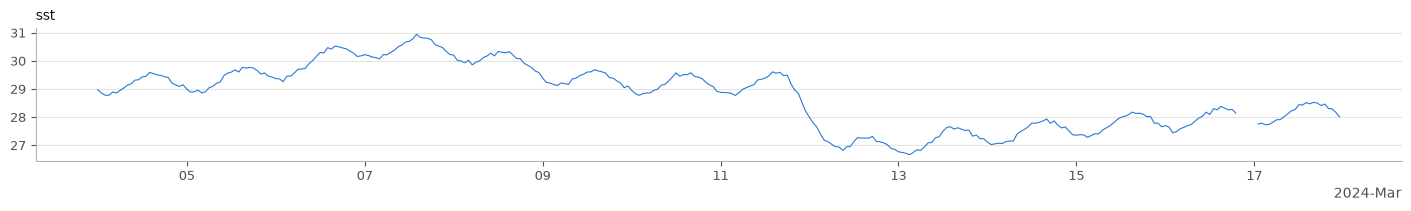

In [3]:
fig, axes = plot_panels(data, "sst", panel_height=2.0)

## Layout

The layout lists the panels from top to bottom. A `Panel` is one subplot and holds one or more `Line` objects,
which share its y axis. A line without a label is not listed in the legend. `height` is relative to the other
panels; `panel_height` (in inches) is the height of a panel with `height=1`. Below, the lines of the panels with
one line have no label, because the panel title already names them.

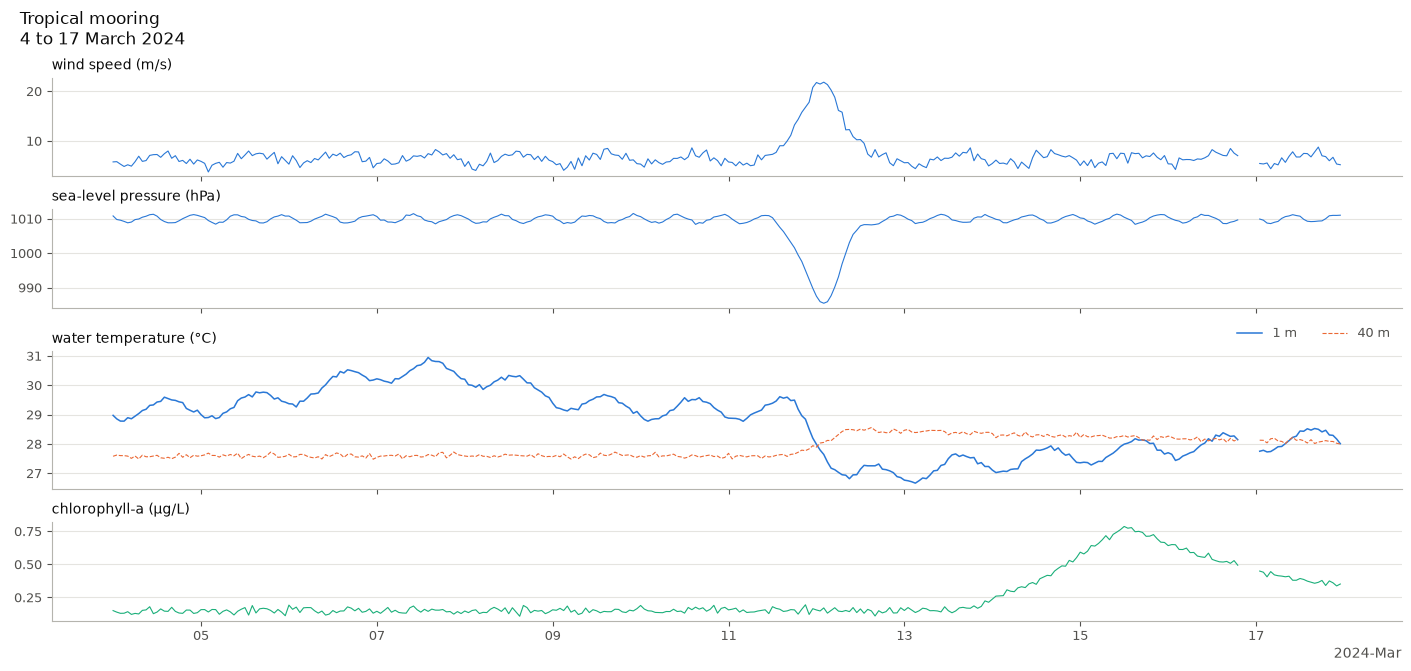

In [4]:
layout = [
    Panel([Line("wind")], title="wind speed (m/s)"),
    Panel([Line("pressure")], title="sea-level pressure (hPa)"),
    Panel(
        [Line("sst", "1 m", linewidth=1.1), Line("temp_40m", "40 m", linestyle="--")],
        title="water temperature (°C)",
        height=1.4,
    ),
    Panel([Line("chlorophyll", color="series[2]")], title="chlorophyll-a (µg/L)"),
]
fig, axes = plot_panels(data, layout, title="Tropical mooring\n4 to 17 March 2024", panel_height=1.5)

### Shorthand forms

A panel with one line may be written without `Panel` and `Line`: as a column name, as a `(column, title)` pair,
or as a `{column: title}` dict, which gives one panel per column. `as_panels` performs this conversion; its
result shows the `Panel` objects that `plot_panels` draws. A panel with several lines is always written as
`Panel([...])`.

In [5]:
shorthand = ["sst", ("pressure", "sea-level pressure (hPa)"), Line("chlorophyll", "chlorophyll-a", color="series[2]")]
for panel in as_panels(shorthand):
    print(panel)

Panel(lines=[Line(column='sst', label=None, color=None, linewidth=0.8, linestyle='-')], title=None, annotations=(), height=1.0)
Panel(lines=[Line(column='pressure', label=None, color=None, linewidth=0.8, linestyle='-')], title='sea-level pressure (hPa)', annotations=(), height=1.0)
Panel(lines=[Line(column='chlorophyll', label='chlorophyll-a', color='series[2]', linewidth=0.8, linestyle='-')], title=None, annotations=(), height=1.0)


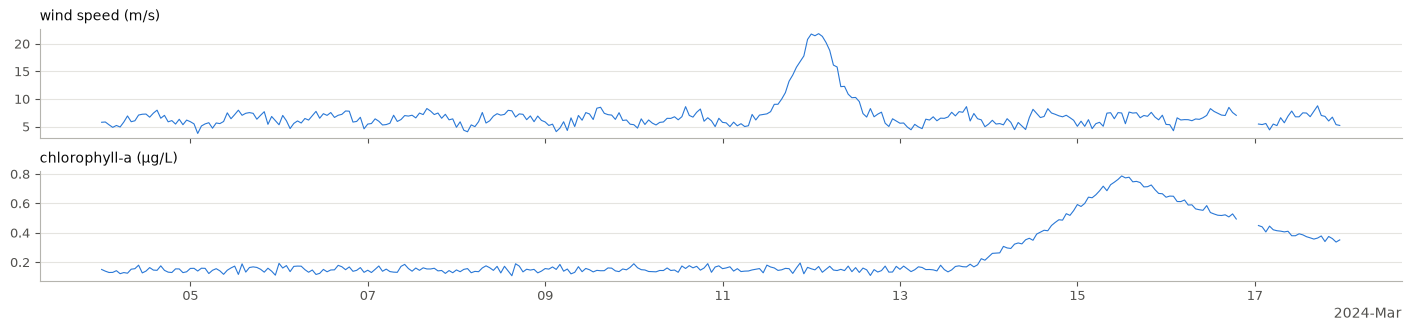

In [6]:
fig, axes = plot_panels(data, {"wind": "wind speed (m/s)", "chlorophyll": "chlorophyll-a (µg/L)"}, panel_height=1.6)

## Input forms

The same layout is drawn from four forms of input; each is converted by `to_frame` to a pandas DataFrame
indexed by time and sorted by time.

- a DataFrame indexed by time, as above;
- a DataFrame with a time column, named by `time`;
- a `{name: Series}` dict, whose Series are joined on time; a time missing from one Series becomes NaN in that
  column;
- a polars DataFrame together with `time` (requires the extra `tspanels[polars]`).

In the dict below, the hourly sea-surface temperature of the mooring is joined with a daily chlorophyll-a value,
as a satellite product would provide it, placed at noon of each day. The joined table therefore has NaN in `chlorophyll_daily` at 23 of
every 24 hours. A line is interrupted at every missing value, so that a column with NaN between all of its
values is drawn as isolated points without connecting segments; such a column is interpolated after the join,
and the joined table is passed to `plot_panels`.

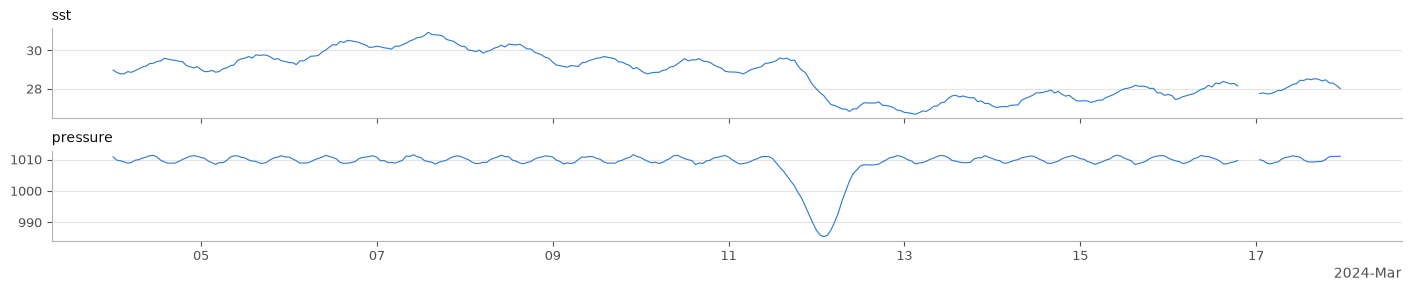

In [7]:
with_column = data.reset_index()  # the time is now the column "time"
fig, axes = plot_panels(with_column, ["sst", "pressure"], time="time", panel_height=1.4)

14 of 336 hours have a daily chlorophyll-a value


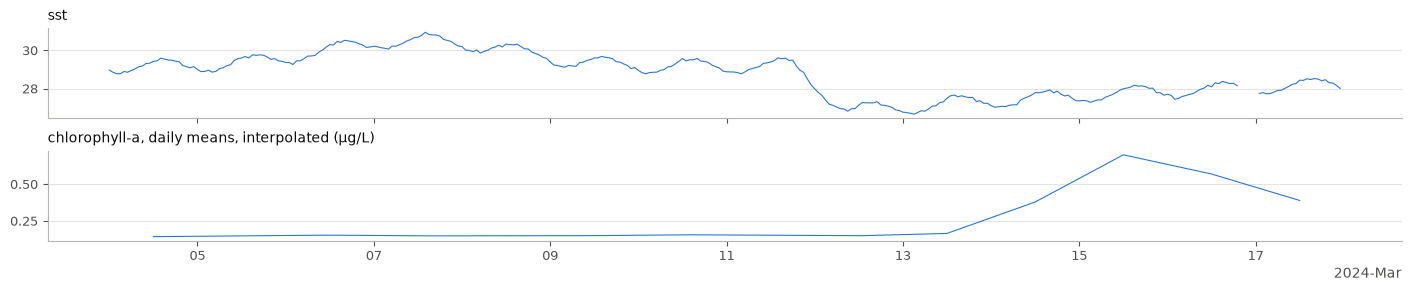

In [8]:
daily = data["chlorophyll"].resample("D").mean()
daily.index += 12 * HOUR  # each daily mean is placed at noon of its day
series = {"sst": data["sst"], "chlorophyll_daily": daily}
joined = to_frame(series)
print(joined["chlorophyll_daily"].notna().sum(), "of", len(joined), "hours have a daily chlorophyll-a value")

joined["chlorophyll_daily"] = joined["chlorophyll_daily"].interpolate(method="time", limit_area="inside")
fig, axes = plot_panels(
    joined, ["sst", ("chlorophyll_daily", "chlorophyll-a, daily means, interpolated (µg/L)")], panel_height=1.4
)

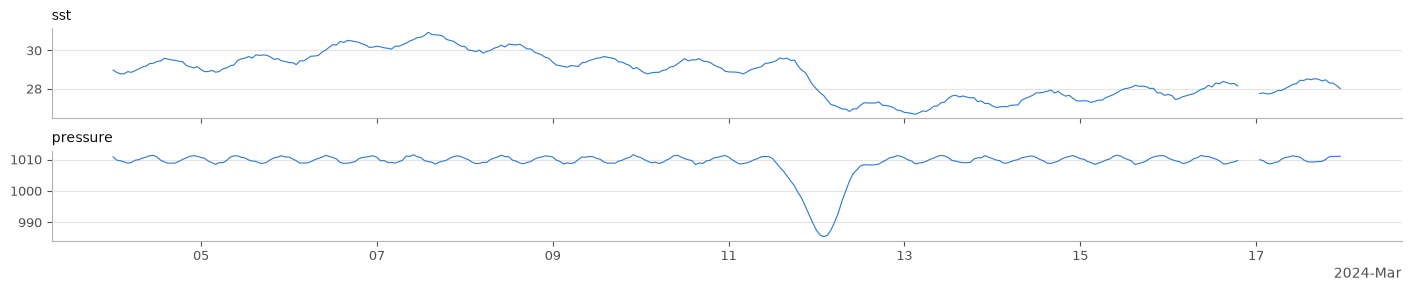

In [9]:
try:
    import polars as pl
except ImportError:
    print("polars is not installed; install the extra tspanels[polars] to run this cell")
else:
    frame = pl.from_pandas(data.reset_index())
    fig, axes = plot_panels(frame, ["sst", "pressure"], time="time", panel_height=1.4)

## Annotations of one panel

An annotation passed to `Panel(annotations=[...])` is drawn in that panel only.

| Annotation | Draws |
|---|---|
| `RefLine(y, label)` | a horizontal reference level; the label is placed outside the right edge |
| `Band(lower, upper, label)` | a range between two edges, each a column name or a fixed value |
| `Points(mask, column, label)` | markers on `column` at the times where `mask` is True |
| `Note(x, text, column=...)` | one marked point; `{x}` and `{y}` in the text are replaced by the time and the value |

In the temperature panel below, the band is the climatological range of the sea-surface temperature for March
(two fixed values), the reference line is the threshold of thermal stress, and the points mark the hours above
it. In the pressure panel, the note marks the lowest pressure of the storm.

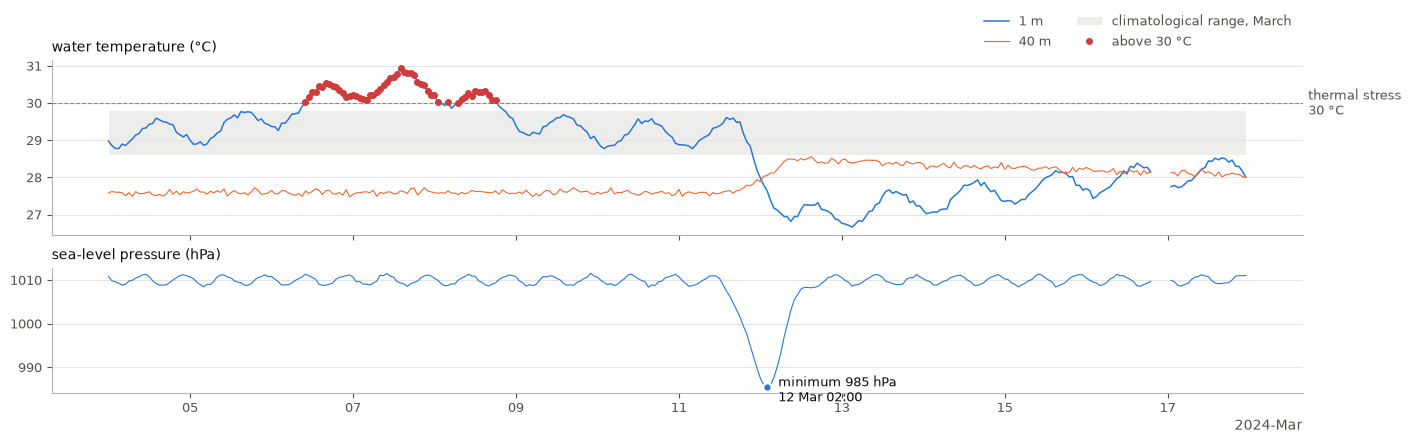

In [10]:
above = data["sst"] > 30
lowest = data["pressure"].idxmin()
layout = [
    Panel(
        [Line("sst", "1 m", linewidth=1.1), Line("temp_40m", "40 m")],
        title="water temperature (°C)",
        annotations=[
            Band(28.6, 29.8, "climatological range, March"),
            RefLine(30, "thermal stress\n30 °C"),
            Points(above, "sst", "above 30 °C"),
        ],
        height=1.4,
    ),
    Panel(
        [Line("pressure")],
        title="sea-level pressure (hPa)",
        annotations=[Note(lowest, "minimum {y:.0f} hPa\n{x:%d %b %H:%M}", column="pressure")],
    ),
]
fig, axes = plot_panels(data, layout, panel_height=1.8)

## Annotations of the whole figure

An annotation passed to `plot_panels(annotations=[...])` is drawn in every panel; typical ones are `Span`
(a shaded period) and `VLine` (an event at one time). Its legend entry appears in the first panel only, so that
it is not repeated; text written on the axes, such as the label of a `VLine`, appears in every panel.

A `Span` ends at `end + HOUR` here, because `EVENTS` stores the last hour of an event and that hour lasts until
the next reading.

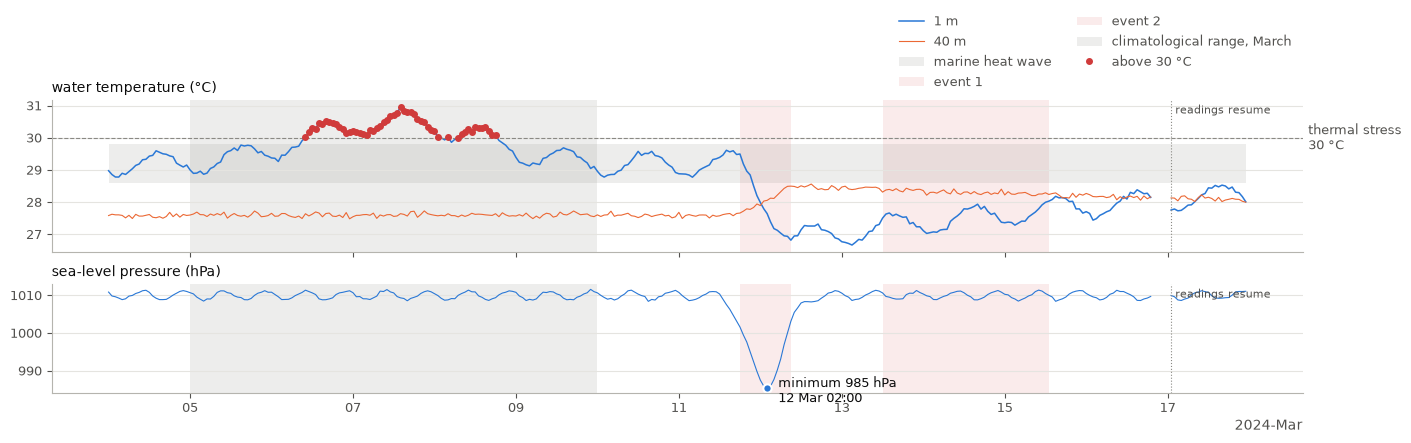

In [11]:
figure_wide = [
    Span("2024-03-05", "2024-03-10", "marine heat wave"),
    *[Span(e.start, e.end + HOUR, f"event {i}", color="alert", alpha=0.10) for i, e in EVENTS.iterrows()],
    VLine("2024-03-17 01:00", "readings resume"),
]
fig, axes = plot_panels(data, layout, annotations=figure_wide, panel_height=1.8)

## Window and gaps

`window=(start, end)` plots only the rows between `start` and `end`, both included. The y axes are scaled to
these rows, and the time axis spans exactly the window, also when an annotation reaches beyond it.

A missing value interrupts a line. `gaps` additionally marks each gap time with a cross along the bottom edge of
every panel: `gaps="no_reading"` marks the times where that column is truthy, and a boolean Series marks the
times where it is True. `gap_label` is the legend entry of the markers.

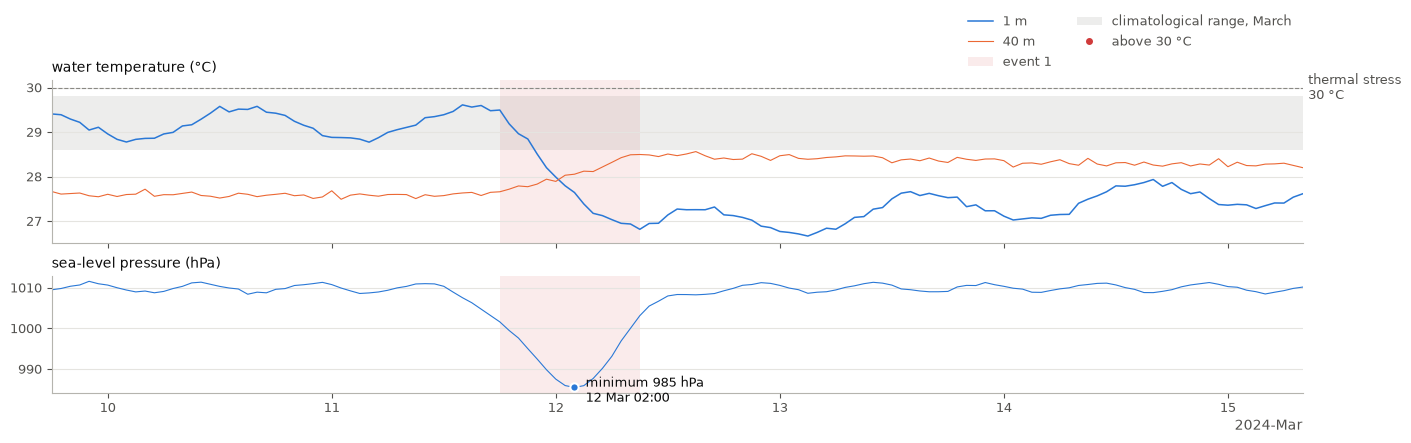

In [12]:
start, end = EVENTS.at[1, "start"], EVENTS.at[1, "end"]
fig, axes = plot_panels(
    data,
    layout,
    window=(start - 48 * HOUR, end + 72 * HOUR),
    annotations=[Span(start, end + HOUR, "event 1", color="alert", alpha=0.10)],
    gaps="no_reading",
    gap_label="no reading",
    panel_height=1.8,
)

A project in which only some tables have a gap column fixes its defaults once with `functools.partial`.
`require_gaps=False` draws no markers when the column is absent, instead of raising `KeyError`; every call can
still override the fixed arguments.

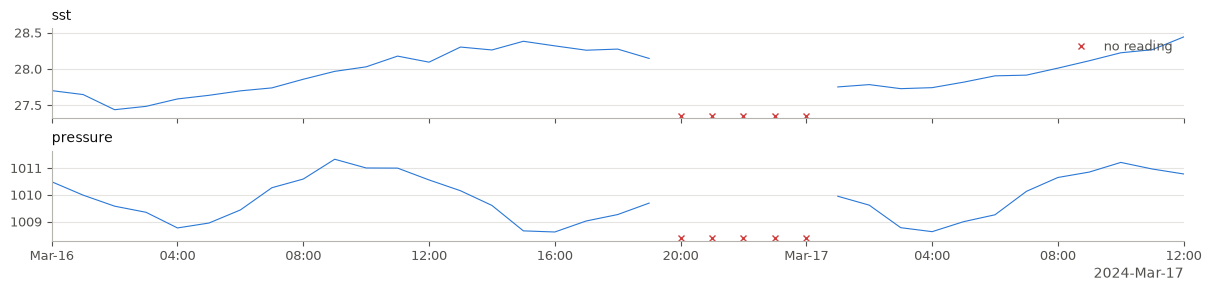

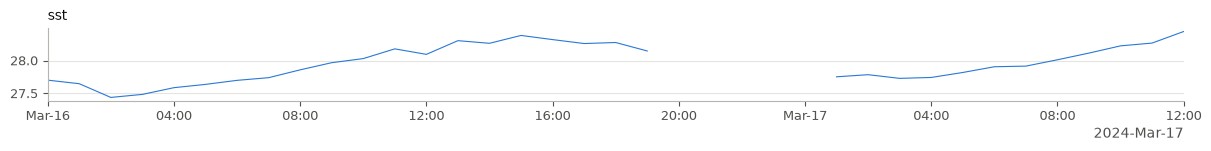

In [13]:
plot = functools.partial(plot_panels, gaps="no_reading", gap_label="no reading", require_gaps=False, width=12)

window = ("2024-03-16", "2024-03-17 12:00")
fig, axes = plot(data, ["sst", "pressure"], window=window, panel_height=1.4)  # markers drawn
fig, axes = plot(data.drop(columns="no_reading"), ["sst"], window=window, panel_height=1.4)  # no column, no markers

## Required columns

`required_columns(panels, annotations, gaps)` returns the columns that a layout refers to, computed from the
layout alone. It selects the columns of a figure from a wider table, for example before a table is copied or
read from a file. `plot_panels` checks the data against the same list before it draws anything.

In [14]:
required_columns(layout, figure_wide, gaps="no_reading")

['sst', 'temp_40m', 'pressure', 'no_reading']

## A project-level plotting function

A project usually draws the same figure for many events. A function that fixes the layout and the window, and
takes the event as its argument, keeps these figures identical. The function below:

- defines the panels of an event figure;
- plots the event with `pad_hours` before and after it;
- passes further keyword arguments to `plot_panels`, with project defaults set by `setdefault`;
- returns the figure, the axes, and the plotted rows inside the window, for a check of the values.

event 1: wind up to 21.8 m/s, pressure down to 985 hPa, chlorophyll-a up to 0.19 µg/L
event 2: wind up to 8.6 m/s, pressure down to 1008 hPa, chlorophyll-a up to 0.79 µg/L


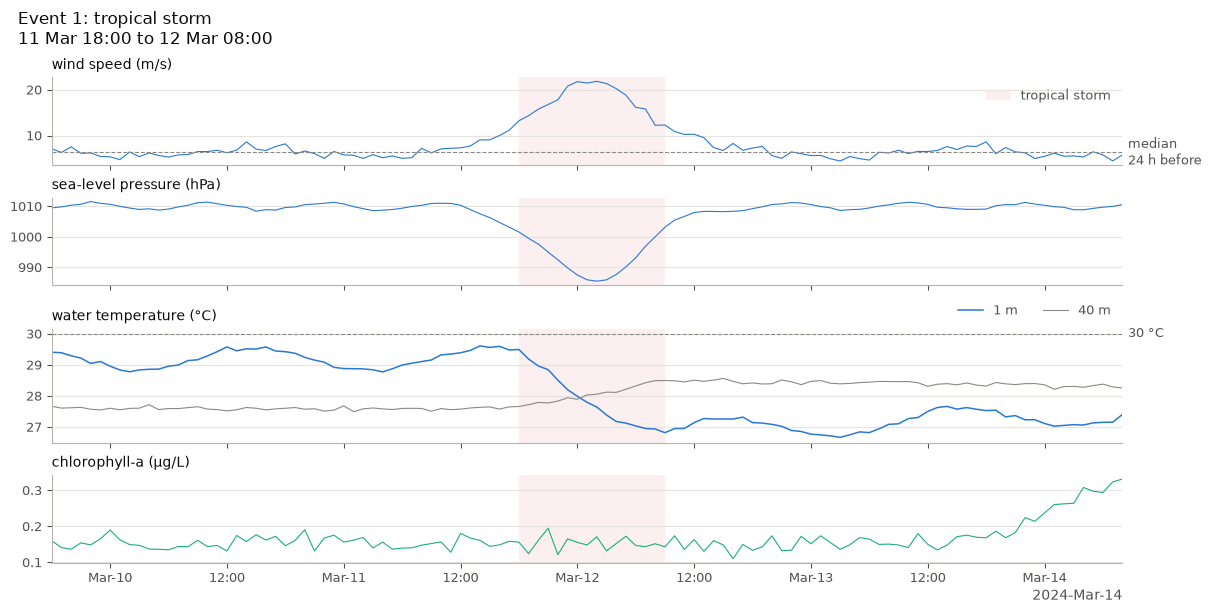

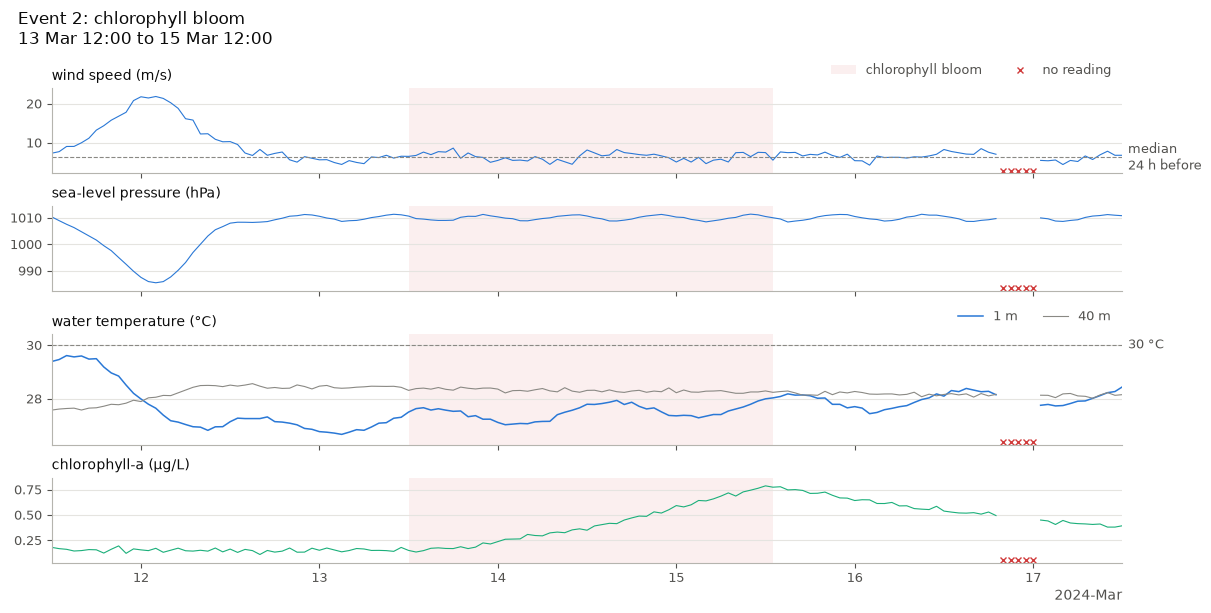

In [15]:
def plot_event(data: pd.DataFrame, start, end, *, label: str = "event", pad_hours: int = 48, **plot_kwargs):
    """Plot one event from ``start`` to ``end`` (the last hour of the event, included)."""
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    window = (start - pad_hours * HOUR, end + pad_hours * HOUR)
    before = data.loc[start - 24 * HOUR : start - HOUR]
    panels = [
        Panel(
            [Line("wind")],
            title="wind speed (m/s)",
            annotations=[RefLine(before["wind"].median(), "median\n24 h before")],
        ),
        Panel([Line("pressure")], title="sea-level pressure (hPa)"),
        Panel(
            [Line("sst", "1 m", linewidth=1.1), Line("temp_40m", "40 m", color="series[3]")],
            title="water temperature (°C)",
            annotations=[RefLine(30, "30 °C")],
            height=1.3,
        ),
        Panel([Line("chlorophyll", color="series[2]")], title="chlorophyll-a (µg/L)"),
    ]
    plot_kwargs.setdefault("panel_height", 1.4)
    plot_kwargs.setdefault("width", 12)
    fig, axes = plot_panels(
        data,
        panels,
        window=window,
        annotations=[Span(start, end + HOUR, label, color="alert", alpha=0.08)],
        gaps="no_reading",
        gap_label="no reading",
        **plot_kwargs,
    )
    return fig, axes, data.loc[window[0] : window[1], required_columns(panels)]


for i, e in EVENTS.iterrows():
    fig, axes, rows = plot_event(
        data, e.start, e.end, label=e.kind, title=f"Event {i}: {e.kind}\n{e.start:%d %b %H:%M} to {e.end:%d %b %H:%M}"
    )
    during = rows.loc[e.start : e.end]
    print(f"event {i}: wind up to {during['wind'].max():.1f} m/s, pressure down to {during['pressure'].min():.0f} hPa, "
          f"chlorophyll-a up to {during['chlorophyll'].max():.2f} µg/L")

## Colors

All colors are fields of the frozen dataclass `Style`. A modified style is created by passing only the fields
to change, and is applied to one figure with `style=`. A color given to a `Line` or an annotation may name a
field of the style (`"alert"`, `"reference"`, `"series[2]"`); it is then taken from the style of the figure
when the figure is drawn. A literal color such as `"#c00000"` is used unchanged.

In [16]:
DEFAULT_STYLE

Style(series=('#2a78d6', '#eb6834', '#1baf7a', '#8a8984'), ink='#0b0b0b', ink_muted='#52514e', axis='#b5b4ae', grid='#e5e4e0', reference='#8a8984', shade='#8a8984', alert='#d03b3b', background='white')

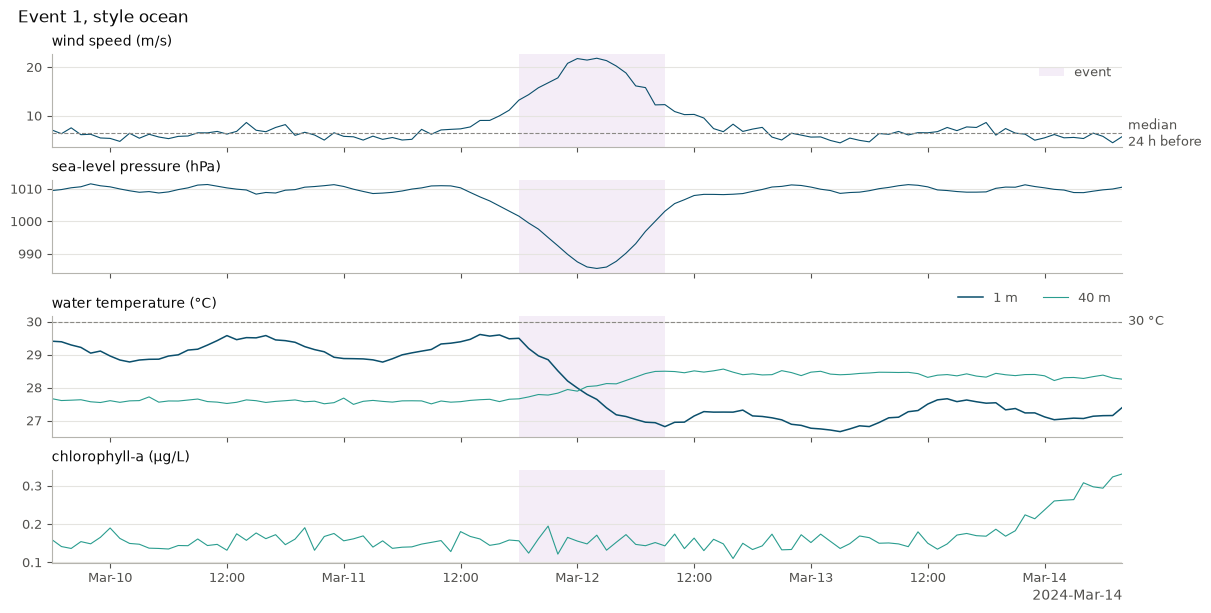

In [17]:
ocean = Style(series=("#0b4f6c", "#e07a5f", "#2a9d8f"), alert="#7a1fa2", shade="#4a6fa5")
fig, axes, _ = plot_event(data, EVENTS.at[1, "start"], EVENTS.at[1, "end"], style=ocean, title="Event 1, style ocean")

`set_default_style` sets the style of every later figure that has no `style=` argument;
`set_default_style(DEFAULT_STYLE)` restores the defaults. A notebook sets it once, after the imports.

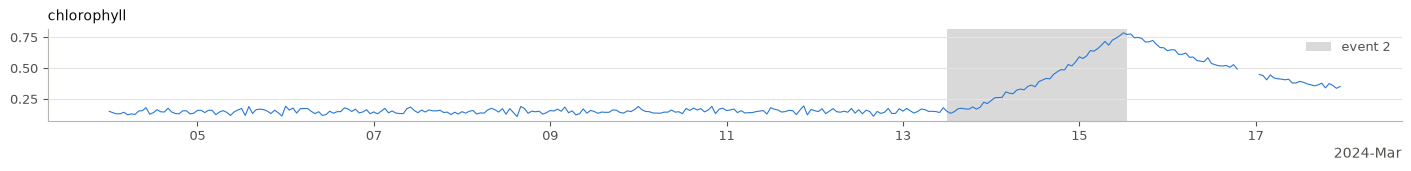

In [18]:
set_default_style(Style(alert="#000000"))
fig, axes = plot_panels(
    data,
    "chlorophyll",
    annotations=[Span(EVENTS.at[2, "start"], EVENTS.at[2, "end"] + HOUR, "event 2", color="alert")],
    panel_height=1.6,
)
set_default_style(DEFAULT_STYLE)

## User-defined annotations

Any object with a method `draw(ax, data, style)` is accepted as an annotation: `ax` is the panel's Axes, `data`
is the plotted DataFrame indexed by time (the rows inside the window), and `style` is the `Style` in effect. An
annotation that reads columns defines `columns()` as well, so that `plot_panels` reports a missing column with
`KeyError` before drawing.

`Runs` below shades every run of consecutive hours where a boolean column is True, here the hours of gale-force
wind (at least 17.2 m/s, Beaufort force 8). As a figure-wide annotation it is drawn in every panel and listed in
the legend of the first panel only.

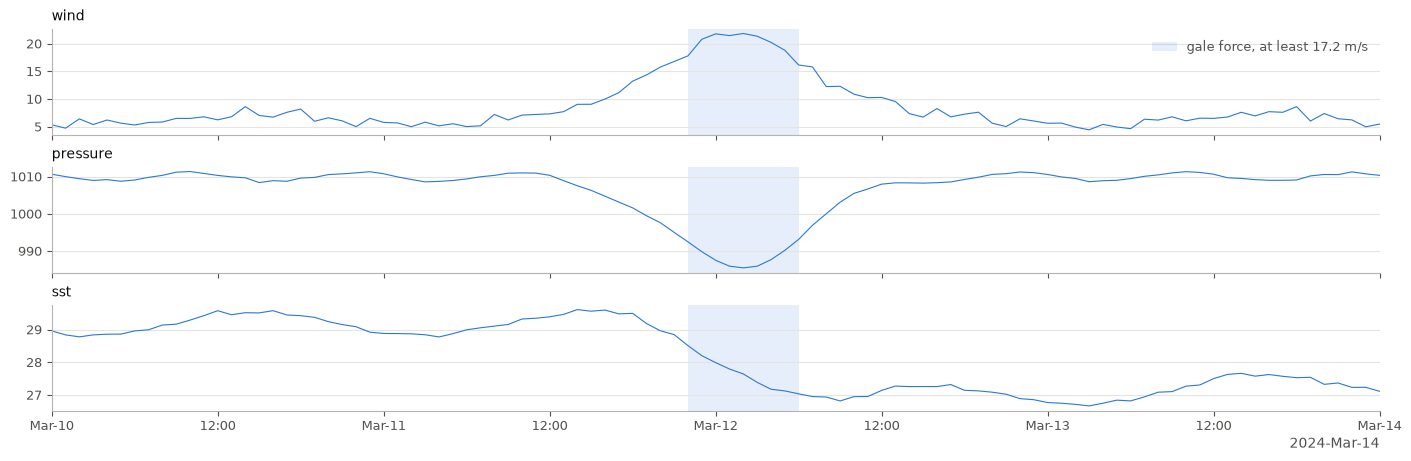

In [19]:
@dataclass(frozen=True)
class Runs:
    """Shade each run of consecutive rows where the boolean column ``mask`` is True."""

    mask: str
    label: str | None = None
    color: str | None = "alert"
    alpha: float = 0.12

    def columns(self) -> list[str]:
        return [self.mask]

    def draw(self, ax, data, style) -> None:
        flag = data[self.mask].fillna(False).astype(bool).to_numpy()
        edges = np.diff(np.r_[0, flag.astype(int), 0])
        starts, ends = np.flatnonzero(edges == 1), np.flatnonzero(edges == -1) - 1
        step = data.index.to_series().diff().median()
        for k, (s, e) in enumerate(zip(starts, ends)):
            ax.axvspan(data.index[s], data.index[e] + step, color=style.color(self.color), alpha=self.alpha,
                       linewidth=0, label=self.label if k == 0 else None)


data["gale"] = data["wind"] >= 17.2
fig, axes = plot_panels(
    data,
    ["wind", "pressure", "sst"],
    window=("2024-03-10", "2024-03-14"),
    annotations=[Runs("gale", "gale force, at least 17.2 m/s", color="series[0]")],
    panel_height=1.5,
)

## Building blocks

`plot_panels` is composed of functions that are also public: `draw_panel` draws one `Panel` into an existing
Axes, `style_axis` applies the grid and axis style, and `format_time_axis` sets the date ticks. They place a
time panel in a figure with another layout, here next to a scatter plot. `draw_panel` expects a DataFrame
indexed by time, which `to_frame` returns for every accepted input.

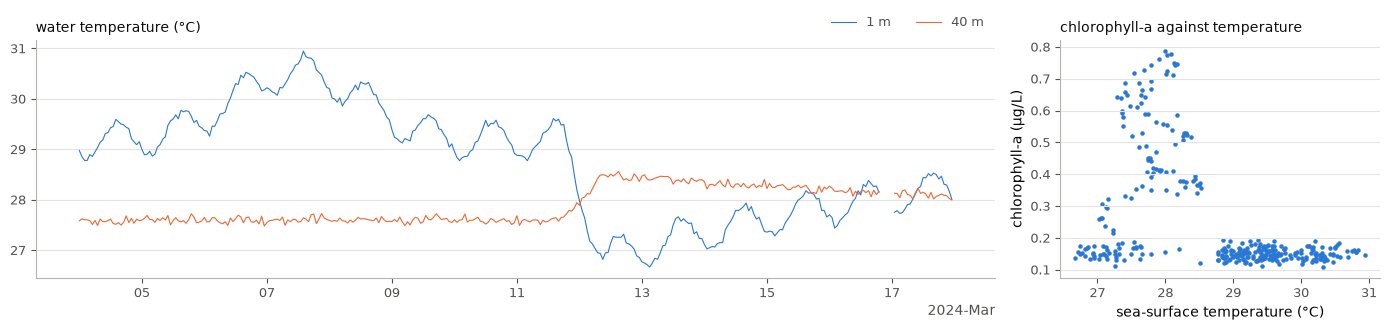

In [20]:
frame = to_frame(data)
fig, (ax_time, ax_scatter) = plt.subplots(1, 2, figsize=(14, 3.4), gridspec_kw={"width_ratios": [3, 1]})

draw_panel(ax_time, frame, Panel([Line("sst", "1 m"), Line("temp_40m", "40 m")], title="water temperature (°C)"))
format_time_axis(ax_time)

ax_scatter.scatter(frame["sst"], frame["chlorophyll"], s=5, color=DEFAULT_STYLE.series[0])
ax_scatter.set(xlabel="sea-surface temperature (°C)", ylabel="chlorophyll-a (µg/L)")
ax_scatter.set_title("chlorophyll-a against temperature", loc="left", fontsize=10, color=DEFAULT_STYLE.ink)
style_axis(ax_scatter)
fig.tight_layout()

## Theme for other plots

`rc_params()` returns matplotlib settings that give ordinary plots the look of `plot_panels`: titles on the
left, muted tick labels, lines in the `series` colors, a horizontal grid, and no top or right axis line.
`with mpl.rc_context(rc_params()):` applies them to one block; `use_theme()` applies them to the rest of the
process. Importing tspanels never changes matplotlib's settings.

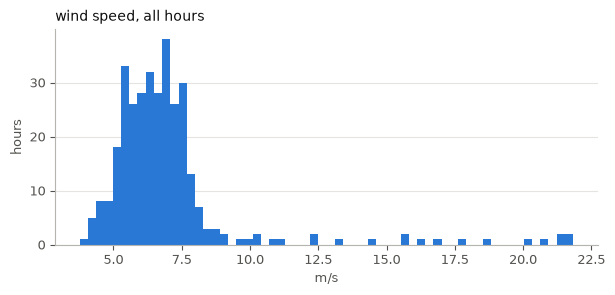

In [21]:
with mpl.rc_context(rc_params()):
    fig, ax = plt.subplots(figsize=(7, 2.8))
    ax.hist(data["wind"].dropna(), bins=60)
    ax.set(title="wind speed, all hours", xlabel="m/s", ylabel="hours")

## Errors

`plot_panels` checks the layout and the data before it draws. A column that the data lacks raises `KeyError`
with the name of the column. A `(column, title)` pair whose title is another column is ambiguous, since it may be
meant as a panel of two lines, and raises `ValueError`. A list of column names inside the layout raises
`TypeError` instead of being interpreted.

In [22]:
attempts = {
    "missing column": lambda: plot_panels(data, "wind_speed"),
    "ambiguous pair": lambda: plot_panels(data, [("sst", "temp_40m")]),
    "list as a panel": lambda: plot_panels(data, [["sst", "temp_40m"]]),
    "missing column of an annotation": lambda: plot_panels(data, "sst", annotations=[Runs("rain")]),
}
for name, attempt in attempts.items():
    try:
        attempt()
    except (KeyError, ValueError, TypeError) as error:
        print(f"{name}: {type(error).__name__}: {error}")
plt.close("all")

missing column: KeyError: "columns not in the data: ['wind_speed']"
ambiguous pair: ValueError: the pair ('sst', 'temp_40m') is read as (column, title), but 'temp_40m' is also a column of the data; write Panel(['sst', 'temp_40m']) for two lines in one panel, or Panel('sst', title='temp_40m') for a title
list as a panel: TypeError: a layout item must be a Panel, a Line, a column name, or a (column, title) pair; several lines in one panel are written as Panel([...]), not ['sst', 'temp_40m']
missing column of an annotation: KeyError: "columns not in the data: ['rain']"
